In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

data = pd.read_csv("../data/zomato_ncr_clean.csv")
rated = data[data["is_rated"]]   # use this for anything about ratings
print(data.shape, rated.shape)

(7947, 20) (5808, 20)


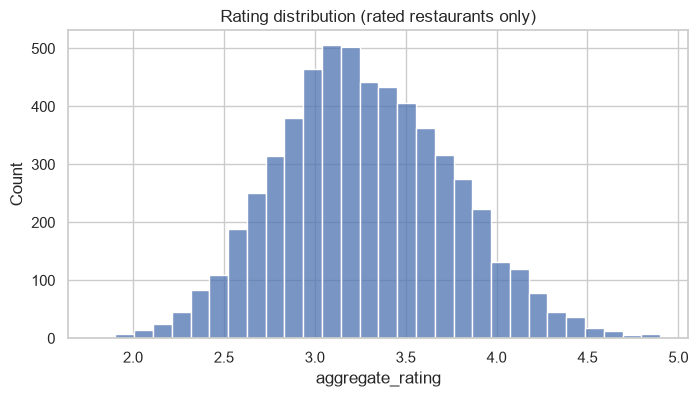

count    5808.00
mean        3.28
std         0.47
min         1.80
25%         3.00
50%         3.30
75%         3.60
max         4.90
Name: aggregate_rating, dtype: float64


In [2]:
plt.figure(figsize=(8,4))
sns.histplot(rated["aggregate_rating"], bins=30)
plt.title("Rating distribution (rated restaurants only)")
plt.show()
print(rated["aggregate_rating"].describe().round(2))

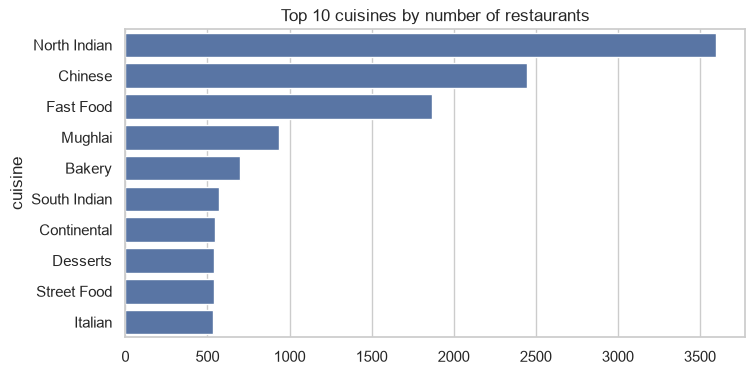

In [3]:
cuisine_df = data.assign(cuisine=data["cuisines"].str.split(", ")).explode("cuisine")
top = cuisine_df["cuisine"].value_counts().head(10)

plt.figure(figsize=(8,4))
sns.barplot(x=top.values, y=top.index)
plt.title("Top 10 cuisines by number of restaurants")
plt.show()

price_range
1    3.18
2    3.25
3    3.57
4    3.65
Name: aggregate_rating, dtype: float64


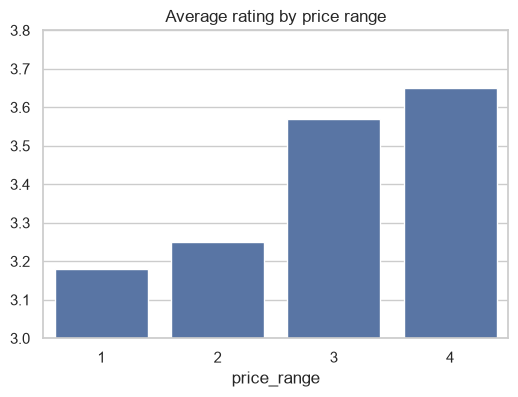

In [4]:
avg = rated.groupby("price_range")["aggregate_rating"].mean().round(2)
print(avg)

plt.figure(figsize=(6,4))
sns.barplot(x=avg.index, y=avg.values)
plt.title("Average rating by price range")
plt.ylim(3, 3.8)
plt.show()

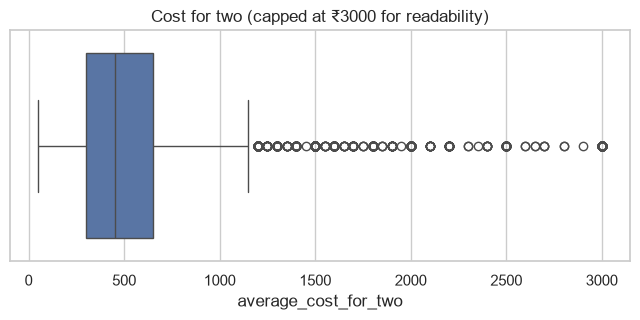

count    7947.0
mean      600.0
std       599.0
min        50.0
25%       300.0
50%       450.0
75%       650.0
max      8000.0
Name: average_cost_for_two, dtype: float64


In [5]:
plt.figure(figsize=(8,3))
sns.boxplot(x=data["average_cost_for_two"].clip(upper=3000))
plt.title("Cost for two (capped at ₹3000 for readability)")
plt.show()
print(data["average_cost_for_two"].describe().round(0))

In [6]:
for col in ["has_table_booking", "has_online_delivery"]:
    print(data[col].value_counts(normalize=True).round(3), "\n")

has_table_booking
No     0.868
Yes    0.132
Name: proportion, dtype: float64 

has_online_delivery
No     0.708
Yes    0.292
Name: proportion, dtype: float64 

